# Derivable Judgement: A Statistical Decision-Making Model

**Scenario:** Data analyst at a public health research organization, using inferential statistics to derive judgements about factors affecting **diabetes** and **hypertension**.

**Dataset:** `health_dataset.csv` — 500 health records (age, weight, gender, region, smoking, exercise, BMI, BP, cholesterol, glucose, diseases, visit date).

# Part A — Theoretical Foundation

1. **Inferential statistics:** Drawing conclusions about a whole population using a sample, via estimation (confidence intervals) and hypothesis testing, while quantifying uncertainty.
2. **Hypothesis testing:** A procedure to decide between the **null hypothesis (H₀)** (no effect/difference) and the **alternative (H₁)**. Components: H₀, H₁, significance level α, test statistic, critical value / p-value, decision.
3. **Confidence interval & critical value:** A CI is a range likely to contain the true parameter (e.g. 95%): estimate ± critical value × standard error. The **critical value** is the cut-off on the test distribution (z, t, χ², F) beyond which H₀ is rejected.
4. **p-value:** Probability of getting a result at least as extreme as observed, assuming H₀ is true. If p < α, reject H₀.
5. **Type I vs Type II:** **Type I (α)** = rejecting a true H₀ (false positive). **Type II (β)** = failing to reject a false H₀ (false negative). Power = 1 − β.
6. **Tests:**
   - **z-test:** compares means/proportions when n is large (≥30) or σ is known.
   - **t-test:** compares means when n is small or σ is unknown (one-sample, two-sample, paired).
   - **Chi-square test:** checks association between two categorical variables (or goodness-of-fit) using observed vs expected counts.
   - **ANOVA:** compares means of 3+ groups at once using the F-statistic (between-group vs within-group variance).
7. **Covariance:** Measures how two variables vary together; sign shows direction, but magnitude depends on units.
8. **Correlation:** Standardised covariance (Pearson r, −1 to +1) showing strength and direction of linear relationship.

# Part B — Data Analysis & Testing

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
pd.set_option('display.max_columns', None)
np.random.seed(7)
ALPHA = 0.05
df = pd.read_csv(r"C:\Users\mukes\ALTARA_PROJECTS\health_dataset.csv")
print(df.shape)
df.head()

(500, 15)


,record_id,age_group,age,weight,gender,region,smoking_status,exercise_frequency,bmi,blood_pressure,diabetes,hypertension,cholesterol_level,glucose_level,visit_date
0,408f8867-0536-4c4b-ba2e-adac8dfaf159,36-45,42,53,Female,East,Non-Smoker,Weekly,19.7,105.1,False,False,160.2,86.7,2024-05-09
1,1beb5dbb-00ad-4493-92ec-d0f223d21221,46-60,47,80,Male,North,Smoker,Daily,24.6,116.0,True,False,157.4,92.6,2024-03-08
2,0b9fc675-1d5f-42df-8597-fc39f88e236a,36-45,38,68,Female,West,Non-Smoker,Weekly,25.7,115.8,True,False,160.3,90.2,2024-10-11
3,7ad782ae-994a-4ec9-9c15-6bc9f8a33ac9,26-35,28,73,Female,North,Former Smoker,Daily,27.5,106.3,False,False,184.8,108.3,2024-12-04
4,0404ef3d-92e7-43b3-bdf0-6195824e5276,26-35,35,53,Male,South,Smoker,Never,18.1,109.5,False,False,151.4,81.2,2023-07-22


In [2]:
df.info()
df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   record_id           500 non-null    str    
 1   age_group           500 non-null    str    
 2   age                 500 non-null    int64  
 3   weight              500 non-null    int64  
 4   gender              500 non-null    str    
 5   region              500 non-null    str    
 6   smoking_status      500 non-null    str    
 7   exercise_frequency  500 non-null    str    
 8   bmi                 500 non-null    float64
 9   blood_pressure      500 non-null    float64
 10  diabetes            500 non-null    bool   
 11  hypertension        500 non-null    bool   
 12  cholesterol_level   500 non-null    float64
 13  glucose_level       500 non-null    float64
 14  visit_date          500 non-null    str    
dtypes: bool(2), float64(4), int64(2), str(7)
memory usage: 88.7 KB


,age,weight,bmi,blood_pressure,cholesterol_level,glucose_level
count,500.00,500.00,500.00,500.00,500.00,500.00
mean,40.40,71.83,25.11,109.55,177.09,89.47
std,14.11,13.14,4.52,10.85,24.78,13.07
min,18.00,34.00,10.80,70.00,99.70,52.60
25%,29.00,63.00,21.80,102.80,160.28,81.30
50%,40.00,71.00,25.05,109.60,176.75,89.70
75%,50.00,80.25,28.20,116.60,194.30,97.90
max,83.00,107.00,41.00,148.30,265.90,128.60


In [3]:
print('Missing values:', df.isna().sum().sum())
print('Diabetes prevalence:', round(df.diabetes.mean(), 3), '| Hypertension prevalence:', round(df.hypertension.mean(), 3))

Missing values: 0
Diabetes prevalence: 0.218 | Hypertension prevalence: 0.15


## B1. Formulating Hypotheses

| # | H₀ | H₁ | Test |
|---|---|---|---|
| H1 | Smoking has no effect on diabetes prevalence | Smoking affects diabetes prevalence | Chi-square |
| H2 | Mean systolic BP of smokers = non-smokers | Means differ | Welch t-test |
| H3 | Mean BMI of males = females | Means differ | Two-sample z-test (n large) |
| H4 | Diabetes rate is the same across age groups | At least one age group differs | One-way ANOVA |
| H5 | No linear relationship between age and BMI | There is a relationship | Pearson correlation |

Significance level **α = 0.05** for all tests.

## B2. Confidence Intervals (95%)

In [4]:
rows = []
for col in ['age', 'weight', 'bmi', 'blood_pressure', 'cholesterol_level', 'glucose_level']:
    x = df[col]; n = len(x); m = x.mean(); se = stats.sem(x)
    lo, hi = stats.t.interval(0.95, n - 1, loc=m, scale=se)
    rows.append([col, round(m, 2), round(x.std(), 2), round(lo, 2), round(hi, 2)])
ci_df = pd.DataFrame(rows, columns=['Variable', 'Mean', 'Std Dev', 'CI Lower', 'CI Upper'])
ci_df

,Variable,Mean,Std Dev,CI Lower,CI Upper
0,age,40.40,14.11,39.16,41.64
1,weight,71.83,13.14,70.68,72.98
2,bmi,25.11,4.52,24.71,25.51
3,blood_pressure,109.55,10.85,108.60,110.51
4,cholesterol_level,177.09,24.78,174.92,179.27
5,glucose_level,89.47,13.07,88.32,90.62


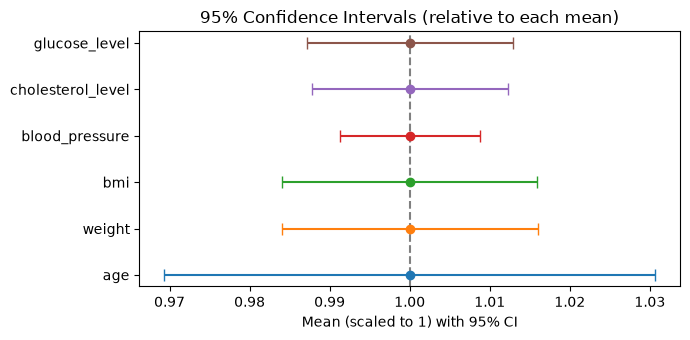

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, r in ci_df.iterrows():
    ax.errorbar(r['Mean'] / r['Mean'], i, xerr=[[ (r['Mean']-r['CI Lower'])/r['Mean']], [ (r['CI Upper']-r['Mean'])/r['Mean']]], fmt='o', capsize=4)
ax.set_yticks(range(len(ci_df))); ax.set_yticklabels(ci_df['Variable'])
ax.axvline(1, color='gray', ls='--'); ax.set_xlabel('Mean (scaled to 1) with 95% CI')
ax.set_title('95% Confidence Intervals (relative to each mean)')
plt.tight_layout(); plt.show()

**Interpretation:** Each interval gives the plausible range of the true population mean. Narrow intervals (large n = 500) mean the sample means are precise estimates.

## B3 & B8. Hypothesis Tests — Critical Values, p-values, Decisions
### H1 — Chi-square: Smoking vs Diabetes

diabetes        False  True 
smoking_status              
Former Smoker      70     15
Non-Smoker        241     54
Smoker             80     40 

Chi-square = 12.3369 | dof = 2 | critical value = 5.9915 | p-value = 0.002095
Decision: REJECT H0


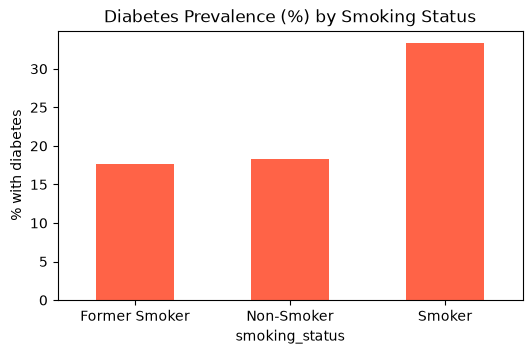

In [6]:
ct = pd.crosstab(df.smoking_status, df.diabetes)
print(ct, '\n')
chi2, p, dof, expected = stats.chi2_contingency(ct)
crit = stats.chi2.ppf(1 - ALPHA, dof)
print(f'Chi-square = {chi2:.4f} | dof = {dof} | critical value = {crit:.4f} | p-value = {p:.6f}')
print('Decision:', 'REJECT H0' if p < ALPHA else 'FAIL TO REJECT H0')
(ct.div(ct.sum(axis=1), axis=0)[True] * 100).round(1).plot(kind='bar', color='tomato', figsize=(6, 3.5), title='Diabetes Prevalence (%) by Smoking Status')
plt.ylabel('% with diabetes'); plt.xticks(rotation=0); plt.show()

**Interpretation:** Since the chi-square statistic exceeds the critical value and p < 0.05, we **reject H₀** — smoking status is significantly associated with diabetes prevalence (smokers show the highest rate).

### H2 — Welch t-test: Blood Pressure, Smokers vs Non-Smokers

Mean BP Smoker = 111.76, Non-Smoker = 108.66
t = 2.5572 | df = 212.3 | critical value = ±1.9712 | p-value = 0.011249
Decision: REJECT H0


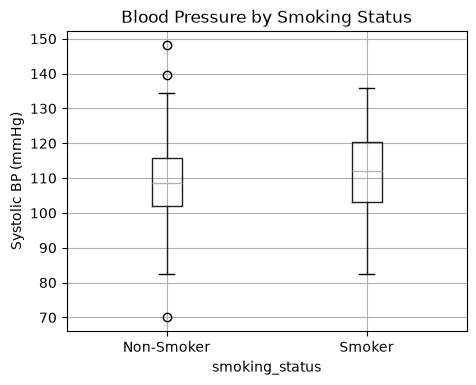

In [7]:
a = df[df.smoking_status == 'Smoker'].blood_pressure
b = df[df.smoking_status == 'Non-Smoker'].blood_pressure
t, p = stats.ttest_ind(a, b, equal_var=False)
dfree = (a.var()/len(a) + b.var()/len(b))**2 / ((a.var()/len(a))**2/(len(a)-1) + (b.var()/len(b))**2/(len(b)-1))
tcrit = stats.t.ppf(1 - ALPHA/2, dfree)
print(f'Mean BP Smoker = {a.mean():.2f}, Non-Smoker = {b.mean():.2f}')
print(f't = {t:.4f} | df = {dfree:.1f} | critical value = ±{tcrit:.4f} | p-value = {p:.6f}')
print('Decision:', 'REJECT H0' if p < ALPHA else 'FAIL TO REJECT H0')
df[df.smoking_status.isin(['Smoker','Non-Smoker'])].boxplot(column='blood_pressure', by='smoking_status', figsize=(5,4))
plt.title('Blood Pressure by Smoking Status'); plt.suptitle(''); plt.ylabel('Systolic BP (mmHg)'); plt.show()

**Interpretation:** |t| = 2.56 exceeds the critical value ±1.97 and p = 0.011 < 0.05, so we **reject H₀** — smokers have a significantly higher mean systolic BP (≈111.8 vs ≈108.7 mmHg).

### H3 — Two-sample z-test: BMI, Male vs Female (n large)

In [8]:
m = df[df.gender == 'Male'].bmi; f = df[df.gender == 'Female'].bmi
z = (m.mean() - f.mean()) / np.sqrt(m.var(ddof=1)/len(m) + f.var(ddof=1)/len(f))
p = 2 * (1 - stats.norm.cdf(abs(z)))
zcrit = stats.norm.ppf(1 - ALPHA/2)
print(f'Mean BMI Male = {m.mean():.2f}, Female = {f.mean():.2f}')
print(f'z = {z:.4f} | critical value = ±{zcrit:.4f} | p-value = {p:.6f}')
print('Decision:', 'REJECT H0' if p < ALPHA else 'FAIL TO REJECT H0')

Mean BMI Male = 25.51, Female = 24.82
z = 1.6960 | critical value = ±1.9600 | p-value = 0.089879
Decision: FAIL TO REJECT H0


**Interpretation:** Both groups have n > 30, so a z-test is valid. |z| = 1.70 < 1.96 and p = 0.090 > 0.05, so we **fail to reject H₀** — no statistically significant BMI difference between males and females.

### H4 — One-way ANOVA: Diabetes Rate across Age Groups

age_group
18-25     6.6
26-35    17.2
36-45    20.9
46-60    30.0
60+      44.2 

F = 8.1626 | df = (4, 495) | critical value = 2.3899 | p-value = 0.000002
Decision: REJECT H0


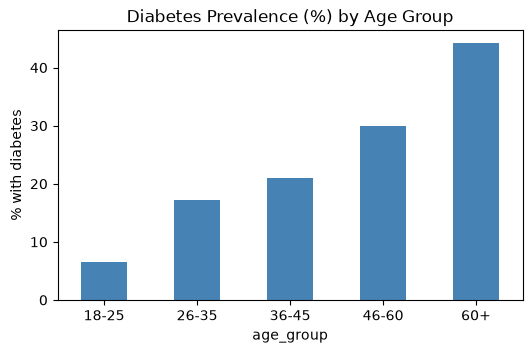

In [9]:
order = ['18-25', '26-35', '36-45', '46-60', '60+']
groups = [df[df.age_group == g].diabetes.astype(int) for g in order]
F, p = stats.f_oneway(*groups)
k, N = len(groups), len(df)
Fcrit = stats.f.ppf(1 - ALPHA, k - 1, N - k)
print((df.groupby('age_group').diabetes.mean().reindex(order) * 100).round(1).to_string(), '\n')
print(f'F = {F:.4f} | df = ({k-1}, {N-k}) | critical value = {Fcrit:.4f} | p-value = {p:.6f}')
print('Decision:', 'REJECT H0' if p < ALPHA else 'FAIL TO REJECT H0')
(df.groupby('age_group').diabetes.mean().reindex(order) * 100).plot(kind='bar', color='steelblue', figsize=(6, 3.5), title='Diabetes Prevalence (%) by Age Group')
plt.ylabel('% with diabetes'); plt.xticks(rotation=0); plt.show()

**Interpretation:** F = 8.16 exceeds the critical value 2.39 and p < 0.001, so we **reject H₀** — diabetes prevalence differs significantly across age groups, rising from ≈6.6% (18-25) to ≈44.2% (60+).

## B7. Covariance & Correlation

In [10]:
cols = ['age', 'weight', 'bmi', 'blood_pressure', 'cholesterol_level', 'glucose_level']
print('Covariance (Age vs BMI):', round(df.age.cov(df.bmi), 4))
r, p = stats.pearsonr(df.age, df.bmi)
print(f'Pearson r (Age vs BMI) = {r:.4f}, p-value = {p:.6f}')
print('Decision (H5):', 'REJECT H0' if p < ALPHA else 'FAIL TO REJECT H0')
print('\nCovariance matrix:'); display(df[cols].cov().round(2))
print('Correlation matrix:'); display(df[cols].corr().round(3))

Covariance (Age vs BMI): 4.6344
Pearson r (Age vs BMI) = 0.0727, p-value = 0.104337
Decision (H5): FAIL TO REJECT H0

Covariance matrix:


,age,weight,bmi,blood_pressure,cholesterol_level,glucose_level
age,198.96,2.63,4.63,57.30,125.74,56.71
weight,2.63,172.58,48.40,40.34,74.91,48.80
bmi,4.63,48.40,20.41,19.95,38.16,25.67
blood_pressure,57.30,40.34,19.95,117.71,70.25,37.99
cholesterol_level,125.74,74.91,38.16,70.25,613.86,93.28
glucose_level,56.71,48.80,25.67,37.99,93.28,170.93


Correlation matrix:


,age,weight,bmi,blood_pressure,cholesterol_level,glucose_level
age,1.000,0.014,0.073,0.374,0.360,0.307
weight,0.014,1.000,0.815,0.283,0.230,0.284
bmi,0.073,0.815,1.000,0.407,0.341,0.435
blood_pressure,0.374,0.283,0.407,1.000,0.261,0.268
cholesterol_level,0.360,0.230,0.341,0.261,1.000,0.288
glucose_level,0.307,0.284,0.435,0.268,0.288,1.000


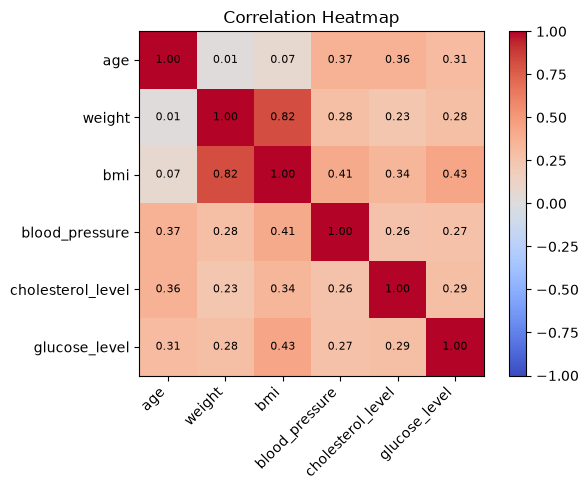

In [11]:
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha='right'); ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)): ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im); ax.set_title('Correlation Heatmap'); plt.tight_layout(); plt.show()

**Interpretation:** Age vs BMI: covariance ≈ 4.63 (positive) and r ≈ 0.073 (p = 0.104 > 0.05), so we **fail to reject H₀** — no significant linear relationship. Covariance shows direction only (unit-dependent); correlation is standardised. In the heatmap, BP, cholesterol and glucose correlate positively with age and BMI.

## Final Summary of Judgements

In [12]:
summary = pd.DataFrame([
 ['H1 Smoking vs Diabetes', 'Chi-square', 'REJECT H0' if stats.chi2_contingency(pd.crosstab(df.smoking_status, df.diabetes))[1] < ALPHA else 'FAIL TO REJECT H0'],
 ['H2 BP: Smoker vs Non-Smoker', 'Welch t-test', 'REJECT H0' if stats.ttest_ind(a, b, equal_var=False)[1] < ALPHA else 'FAIL TO REJECT H0'],
 ['H3 BMI: Male vs Female', 'z-test', 'REJECT H0' if 2*(1-stats.norm.cdf(abs(z))) < ALPHA else 'FAIL TO REJECT H0'],
 ['H4 Diabetes across age groups', 'ANOVA', 'REJECT H0' if stats.f_oneway(*groups)[1] < ALPHA else 'FAIL TO REJECT H0'],
 ['H5 Age vs BMI correlation', 'Pearson', 'REJECT H0' if stats.pearsonr(df.age, df.bmi)[1] < ALPHA else 'FAIL TO REJECT H0'],
], columns=['Hypothesis', 'Test', 'Decision (α=0.05)'])
summary

,Hypothesis,Test,Decision (α=0.05)
0,H1 Smoking vs Diabetes,Chi-square,REJECT H0
1,H2 BP: Smoker vs Non-Smoker,Welch t-test,REJECT H0
2,H3 BMI: Male vs Female,z-test,FAIL TO REJECT H0
3,H4 Diabetes across age groups,ANOVA,REJECT H0
4,H5 Age vs BMI correlation,Pearson,FAIL TO REJECT H0


**Conclusion:** Smoking and age are the clearest drivers of disease occurrence in this dataset, while gender shows no meaningful BMI difference. Statistical evidence, not intuition, supports the judgements above.